# ECG Arrhythmia Classification Using PyTorch CNN

## Overview

This notebook implements a one-dimensional Convolutional Neural Network (1D CNN) using PyTorch for ECG heartbeat classification.

CNNs are particularly useful for extracting local patterns from sequential and signal-based data.

In this project, the CNN learns morphological features directly from ECG waveforms and maps them into one of five heartbeat categories.

Two experiments are conducted:

1. CNN with standard CrossEntropyLoss.
2. CNN with class-weighted CrossEntropyLoss.

The objective is to investigate the effect of class weighting on classification performance in an imbalanced dataset.

## 1. Objectives

1. Prepare ECG signals for one-dimensional convolution.
2. Implement a custom PyTorch Dataset and DataLoader.
3. Design a 1D CNN architecture.
4. Train the CNN using standard CrossEntropyLoss.
5. Introduce class weighting to address class imbalance.
6. Implement early stopping and checkpoint saving.
7. Evaluate both experiments using classification metrics.
8. Compare the effect of weighted and unweighted loss functions.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
print(torch.__version__)

2.11.0+cu128


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
torch.manual_seed(0)

In [4]:
!nvidia-smi

Sun Nov 22 00:13:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.66                 Driver Version: 591.66         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   45C    P8              1W /   47W |    1463MiB /   6141MiB |     15%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Dataset Preparation

The CNN experiments use the training and validation subsets created in the initial EDA and baseline notebook.

The same saved split indices are reused to maintain consistency across all model experiments.

Each ECG signal contains 187 numerical samples.

For a one-dimensional CNN, the input is reshaped into:

`(batch_size, channels, sequence_length)`

Therefore, the expected model input shape is:

`(batch_size, 1, 187)`

The target labels are converted into integer tensors suitable for multiclass classification.


In [5]:
train_df = pd.read_csv("../data/raw/mitbih_train.csv")
train_df.head()

,9.779411554336547852e-01,9.264705777168273926e-01,6.813725233078002930e-01,2.450980395078659058e-01,1.544117629528045654e-01,1.911764740943908691e-01,1.519607901573181152e-01,8.578431606292724609e-02,5.882352963089942932e-02,4.901960864663124084e-02,...,0.000000000000000000e+00.79,0.000000000000000000e+00.80,0.000000000000000000e+00.81,0.000000000000000000e+00.82,0.000000000000000000e+00.83,0.000000000000000000e+00.84,0.000000000000000000e+00.85,0.000000000000000000e+00.86,0.000000000000000000e+00.87,0.000000000000000000e+00.88
0,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.927461,1.000000,0.626943,0.193437,0.094991,0.072539,0.043178,0.053541,0.093264,0.189983,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
X = train_df.iloc[:,:-1]
y = train_df.iloc[:,-1]

In [7]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("X dtype:", X.dtypes.unique())
print("y dtype:", y.dtype)

X shape: (87553, 187)
y shape: (87553,)
X dtype: [dtype('float64')]
y dtype: float64


In [8]:
indices = np.arange(len(X))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=y
)

np.save("../data/processed/train_idx.npy", train_idx)
np.save("../data/processed/val_idx.npy", val_idx)

train_X = X.iloc[train_idx]
val_X = X.iloc[val_idx]

train_y = y.iloc[train_idx]
val_y = y.iloc[val_idx]

In [9]:
train_features = train_X
train_labels = train_y

val_features = val_X
val_labels = val_y

In [10]:
train_features = torch.tensor(train_features.to_numpy(), dtype=torch.float32)
train_labels = torch.tensor(train_labels.to_numpy(), dtype=torch.long)

val_features = torch.tensor(val_features.to_numpy(), dtype=torch.float32)
val_labels = torch.tensor(val_labels.to_numpy(), dtype=torch.long)

## 3. PyTorch Dataset and DataLoader

A custom Dataset class is implemented by inheriting from `torch.utils.data.Dataset`.

The class provides:

- `__init__()` to store features and labels.
- `__len__()` to return the number of samples.
- `__getitem__()` to retrieve an individual ECG signal and its label.

DataLoaders are created for both training and validation datasets.

The training DataLoader uses shuffling, whereas the validation DataLoader preserves sample order.


In [11]:
class ECGDataset(Dataset):
    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        signal = self.features[idx]
        label = self.labels[idx]

        return signal, label

In [12]:
train_dataset = ECGDataset(train_features, train_labels)
val_dataset = ECGDataset(val_features, val_labels)

In [13]:
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))

print("Signal shape:", train_dataset[0][0].shape)
print("Label:", train_dataset[0][1])

Training: 74420
Validation: 13133
Signal shape: torch.Size([187])
Label: tensor(0)


In [14]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True,pin_memory=True)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False,pin_memory=True)

## 4. 1D CNN Architecture

The CNN architecture consists of three convolutional blocks followed by a classification head.

### Convolutional Blocks

**Block 1**
- Conv1D: 1 input channel, 32 output channels, kernel size 7.
- Batch Normalization.
- ReLU activation.
- Max Pooling.

**Block 2**
- Conv1D: 32 input channels, 64 output channels, kernel size 5.
- Batch Normalization.
- ReLU activation.
- Max Pooling.

**Block 3**
- Conv1D: 64 input channels, 128 output channels, kernel size 3.
- Batch Normalization.
- ReLU activation.
- Max Pooling.

### Classification Head

Adaptive Average Pooling reduces the temporal dimension to one value per feature channel.

The resulting representation is flattened and passed through a linear layer to produce five output logits.

The model returns raw logits, which are directly supplied to CrossEntropyLoss.

In [15]:
class ECG_CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.features(x)
        x = self.classifier(x)

        return x


## 5. Training Configuration

The CNN is trained using PyTorch with the following training components:

- Loss function: CrossEntropyLoss.
- Optimizer: The configured optimizer used in the experiment.
- Maximum epochs: 50.
- Batch size: 32.
- Early stopping: Patience of 8 epochs.
- Model selection: Best validation Macro-F1.

Training and validation losses are monitored throughout training.

The model checkpoint is updated whenever a better validation Macro-F1 score is achieved.

Early stopping prevents unnecessary training once validation performance stops improving.

## 6. Experiment 1 - CNN with Standard CrossEntropyLoss

The first experiment trains the CNN using standard CrossEntropyLoss without manually assigning class weights.

This experiment establishes the performance of the CNN under the original class distribution.

The best checkpoint is selected using validation Macro-F1.

Training history, classification report and confusion matrix are saved for further analysis.

In [16]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0
best_epoch = 0

model_plain = ECG_CNN().to(device)
criterion_plain = nn.CrossEntropyLoss()
optimizer_plain = optim.Adam(model_plain.parameters(), lr=learning_rate)

history_plain = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    model_plain.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_plain.zero_grad()

        outputs = model_plain(features)

        loss = criterion_plain(outputs, labels)

        loss.backward()

        optimizer_plain.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    model_plain.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = model_plain(features)

            loss = criterion_plain(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_plain["epoch"].append(epoch + 1)
    history_plain["train_loss"].append(avg_train_loss)
    history_plain["val_loss"].append(avg_val_loss)
    history_plain["accuracy"].append(accuracy)
    history_plain["balanced_accuracy"].append(balanced_acc)
    history_plain["precision"].append(precision)
    history_plain["recall"].append(recall)
    history_plain["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            model_plain.state_dict(),
            "../models/cnn_plain.pt"
        )

        print("Best Plain CNN model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best Plain CNN model saved!
Epoch [1/50] Train Loss: 0.2004 | Val Loss: 0.1375 | Accuracy: 0.9589 | Balanced Acc: 0.6648 | Macro F1: 0.7289
Best Plain CNN model saved!
Epoch [2/50] Train Loss: 0.1251 | Val Loss: 0.1523 | Accuracy: 0.9590 | Balanced Acc: 0.8374 | Macro F1: 0.8361
Epoch [3/50] Train Loss: 0.1094 | Val Loss: 0.1095 | Accuracy: 0.9685 | Balanced Acc: 0.8161 | Macro F1: 0.8356
Best Plain CNN model saved!
Epoch [4/50] Train Loss: 0.0999 | Val Loss: 0.0886 | Accuracy: 0.9750 | Balanced Acc: 0.8502 | Macro F1: 0.8770
Epoch [5/50] Train Loss: 0.0933 | Val Loss: 0.1076 | Accuracy: 0.9687 | Balanced Acc: 0.8352 | Macro F1: 0.8589
Epoch [6/50] Train Loss: 0.0882 | Val Loss: 0.0969 | Accuracy: 0.9753 | Balanced Acc: 0.8765 | Macro F1: 0.8761
Best Plain CNN model saved!
Epoch [7/50] Train Loss: 0.0845 | Val Loss: 0.0854 | Accuracy: 0.9769 | Balanced Acc: 0.8658 | Macro F1: 0.8908
Epoch [8/50] Train Loss: 0.0799 | Val Loss: 0.0879 | Accuracy: 0.9756 | Balanced Acc: 0.8316 | Macro F1:

In [17]:
history_plain_df = pd.DataFrame(history_plain)

history_plain_df.to_csv(
    "../results/metrics/cnn_plain_history.csv",
    index=False
)

history_plain_df

,epoch,train_loss,val_loss,accuracy,balanced_accuracy,precision,recall,macro_f1
0,1,0.200443,0.137455,0.958882,0.664806,0.945541,0.664806,0.728854
1,2,0.125112,0.152283,0.959034,0.837410,0.847100,0.837410,0.836110
2,3,0.109425,0.109523,0.968476,0.816138,0.884740,0.816138,0.835620
3,4,0.099904,0.088603,0.975025,0.850176,0.910571,0.850176,0.876978
4,5,0.093335,0.107586,0.968705,0.835220,0.902160,0.835220,0.858916
5,6,0.088199,0.096851,0.975329,0.876537,0.877780,0.876537,0.876137
6,7,0.084492,0.085401,0.976928,0.865762,0.924081,0.865762,0.890799
7,8,0.079916,0.087923,0.975634,0.831626,0.950441,0.831626,0.875223
8,9,0.076395,0.079092,0.978908,0.865527,0.927768,0.865527,0.889976
9,10,0.073333,0.078895,0.977842,0.846489,0.948250,0.846489,0.890113


In [18]:
model_plain.load_state_dict(
    torch.load(
        "../models/cnn_plain.pt",
        map_location=device,
        weights_only=True
    )
)

model_plain.eval()
print("Best Plain CNN model loaded successfully!")


all_preds_plain = []
all_labels_plain = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = model_plain(features)

        predictions_plain = torch.argmax(outputs, dim=1)

        all_preds_plain.extend(predictions_plain.cpu().numpy())
        all_labels_plain.extend(labels.cpu().numpy())

Best Plain CNN model loaded successfully!


In [19]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels_plain,
    all_preds_plain,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/cnn_plain_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.986800,0.997148,0.991947,10871.000000
Supraventricular,0.922780,0.717718,0.807432,333.000000
Ventricular,0.972909,0.951613,0.962143,868.000000
Fusion,0.883721,0.791667,0.835165,96.000000
Unknown,0.997904,0.986528,0.992183,965.000000
accuracy,0.984771,0.984771,0.984771,0.984771
macro avg,0.952823,0.888935,0.917774,13133.000000
weighted avg,0.984321,0.984771,0.984170,13133.000000


In [20]:
cm = confusion_matrix(all_labels_plain, all_preds_plain)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/cnn_plain_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10840,18,7,4,2
Supraventricular,90,239,4,0,0
Ventricular,34,2,826,6,0
Fusion,9,0,11,76,0
Unknown,12,0,1,0,952


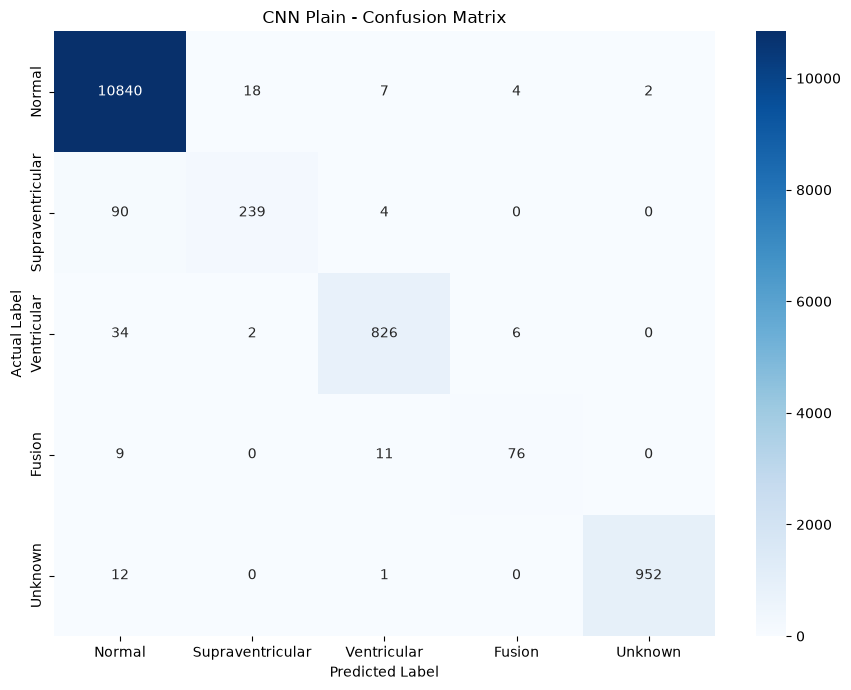

In [21]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Plain - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_plain_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

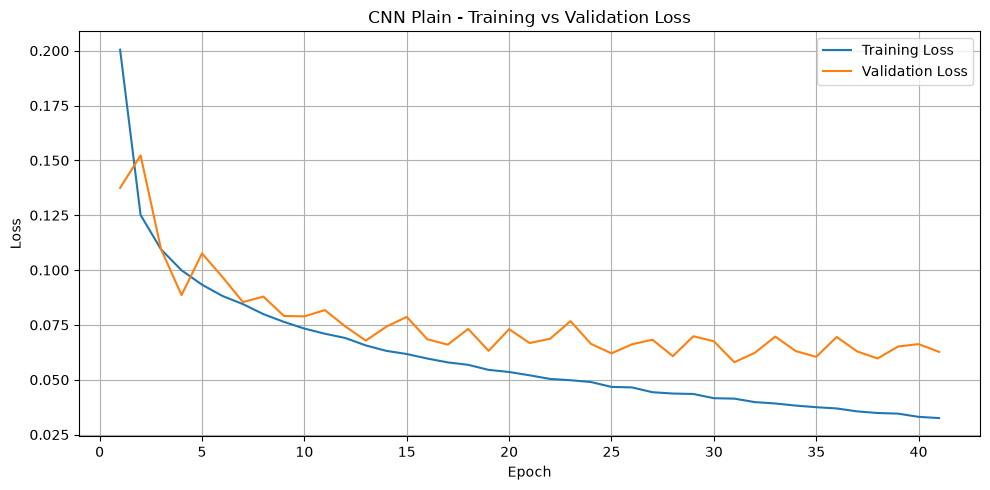

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_plain_df["epoch"],
    history_plain_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_plain_df["epoch"],
    history_plain_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Plain - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_plain_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

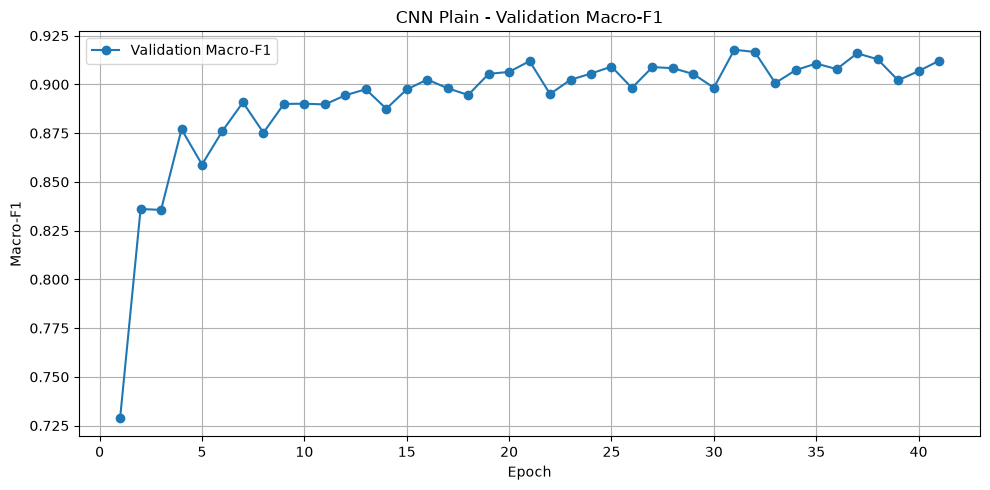

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_plain_df["epoch"],
    history_plain_df["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("CNN Plain - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_plain_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Experiment 2 - CNN with Class-Weighted CrossEntropyLoss

The second experiment introduces class weights calculated using the balanced class-weight strategy.

The weights are passed to CrossEntropyLoss so that errors involving underrepresented classes contribute more strongly to the loss.

A fresh CNN model and optimizer are initialized to ensure that this experiment starts independently of the previous training run.

The purpose is to investigate whether class weighting improves minority-class recognition and overall balanced performance.

In [24]:
classes = np.unique(train_y)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_y
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print(class_weights)

tensor([ 0.2416,  7.8751,  3.0252, 27.3101,  2.7230], device='cuda:0')


In [25]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0
best_epoch = 0

model_weighted = ECG_CNN().to(device)
criterion_weighted = nn.CrossEntropyLoss(weight=class_weights)
optimizer_weighted = optim.Adam(model_weighted.parameters(), lr=learning_rate)

history_weighted = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}



for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    model_weighted.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_weighted.zero_grad()

        outputs = model_weighted(features)

        loss = criterion_weighted(outputs, labels)

        loss.backward()

        optimizer_weighted.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    model_weighted.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = model_weighted(features)

            loss = criterion_weighted(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_weighted["epoch"].append(epoch + 1)
    history_weighted["train_loss"].append(avg_train_loss)
    history_weighted["val_loss"].append(avg_val_loss)
    history_weighted["accuracy"].append(accuracy)
    history_weighted["balanced_accuracy"].append(balanced_acc)
    history_weighted["precision"].append(precision)
    history_weighted["recall"].append(recall)
    history_weighted["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            model_weighted.state_dict(),
            "../models/cnn_weighted.pt"
        )

        print("Best Weighted CNN model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best Weighted CNN model saved!
Epoch [1/50] Train Loss: 0.5621 | Val Loss: 0.3553 | Accuracy: 0.8873 | Balanced Acc: 0.8647 | Macro F1: 0.6809
Epoch [2/50] Train Loss: 0.3685 | Val Loss: 0.3779 | Accuracy: 0.7630 | Balanced Acc: 0.8637 | Macro F1: 0.5997
Best Weighted CNN model saved!
Epoch [3/50] Train Loss: 0.3162 | Val Loss: 0.2833 | Accuracy: 0.9205 | Balanced Acc: 0.8944 | Macro F1: 0.7452
Epoch [4/50] Train Loss: 0.2952 | Val Loss: 0.2973 | Accuracy: 0.9133 | Balanced Acc: 0.8823 | Macro F1: 0.7290
Epoch [5/50] Train Loss: 0.2812 | Val Loss: 0.3540 | Accuracy: 0.7670 | Balanced Acc: 0.8763 | Macro F1: 0.6159
Epoch [6/50] Train Loss: 0.2651 | Val Loss: 0.2848 | Accuracy: 0.8516 | Balanced Acc: 0.8932 | Macro F1: 0.6604
Best Weighted CNN model saved!
Epoch [7/50] Train Loss: 0.2533 | Val Loss: 0.2511 | Accuracy: 0.9420 | Balanced Acc: 0.9072 | Macro F1: 0.7773
Epoch [8/50] Train Loss: 0.2499 | Val Loss: 0.2460 | Accuracy: 0.8610 | Balanced Acc: 0.9065 | Macro F1: 0.7135
Epoch [9/50

In [26]:
history_weighted_df = pd.DataFrame(history_weighted)

history_weighted_df.to_csv(
    "../results/metrics/cnn_weighted_history.csv",
    index=False
)

history_weighted_df

,epoch,train_loss,val_loss,accuracy,balanced_accuracy,precision,recall,macro_f1
0,1,0.562096,0.355262,0.887307,0.864704,0.622665,0.864704,0.680879
1,2,0.368471,0.377917,0.763040,0.863650,0.579312,0.863650,0.599661
2,3,0.316175,0.283337,0.920506,0.894433,0.676765,0.894433,0.745171
3,4,0.295182,0.297271,0.913348,0.882266,0.661184,0.882266,0.728981
4,5,0.281233,0.353999,0.766999,0.876320,0.604460,0.876320,0.615851
5,6,0.265074,0.284787,0.851595,0.893227,0.617979,0.893227,0.660402
6,7,0.253307,0.251094,0.941978,0.907206,0.714230,0.907206,0.777258
7,8,0.249909,0.245995,0.861037,0.906545,0.658163,0.906545,0.713548
8,9,0.229897,0.280929,0.830960,0.898693,0.599908,0.898693,0.669564
9,10,0.221999,0.256244,0.835529,0.901401,0.614331,0.901401,0.654233


In [27]:
model_weighted.load_state_dict(
    torch.load(
        "../models/cnn_weighted.pt",
        map_location=device,
        weights_only=True
    )
)

model_weighted.eval()

print("Best Weighted CNN model loaded successfully!")

all_preds_weighted = []
all_labels_weighted = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = model_weighted(features)

        predictions_weighted = torch.argmax(outputs, dim=1)

        all_preds_weighted.extend(predictions_weighted.cpu().numpy())
        all_labels_weighted.extend(labels.cpu().numpy())

Best Weighted CNN model loaded successfully!


In [28]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels_weighted,
    all_preds_weighted,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/cnn_weighted_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.990948,0.956674,0.973509,10871.000000
Supraventricular,0.443144,0.795796,0.569280,333.000000
Ventricular,0.905495,0.949309,0.926884,868.000000
Fusion,0.521739,0.875000,0.653696,96.000000
Unknown,0.980392,0.984456,0.982420,965.000000
accuracy,0.953552,0.953552,0.953552,0.953552
macro avg,0.768344,0.912247,0.821158,13133.000000
weighted avg,0.967205,0.953552,0.958495,13133.000000


In [29]:
cm = confusion_matrix(all_labels_weighted, all_preds_weighted)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/cnn_weighted_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10400,324,73,56,18
Supraventricular,63,265,2,3,0
Ventricular,20,5,824,18,1
Fusion,4,1,7,84,0
Unknown,8,3,4,0,950


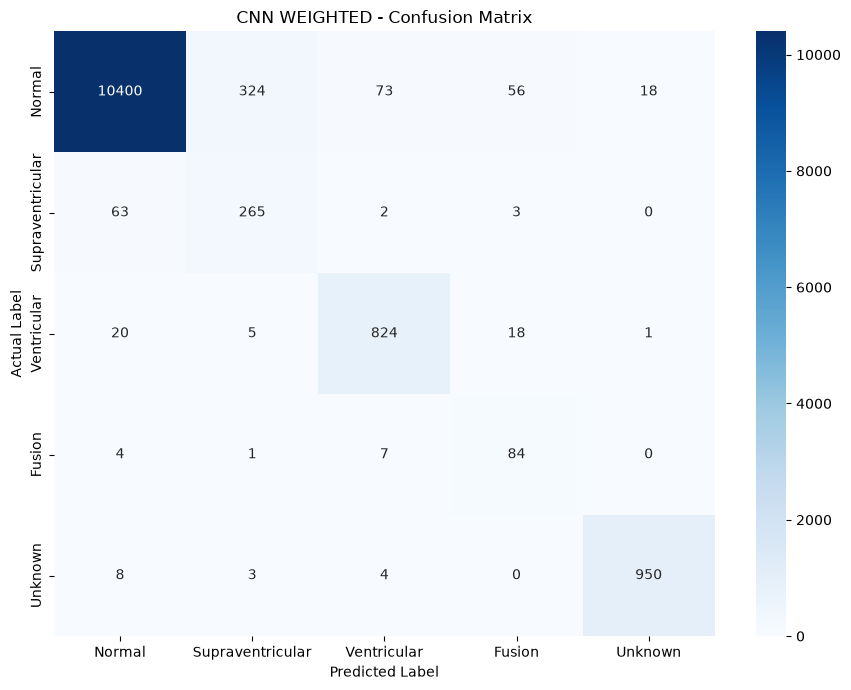

In [30]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN WEIGHTED - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_weighted_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

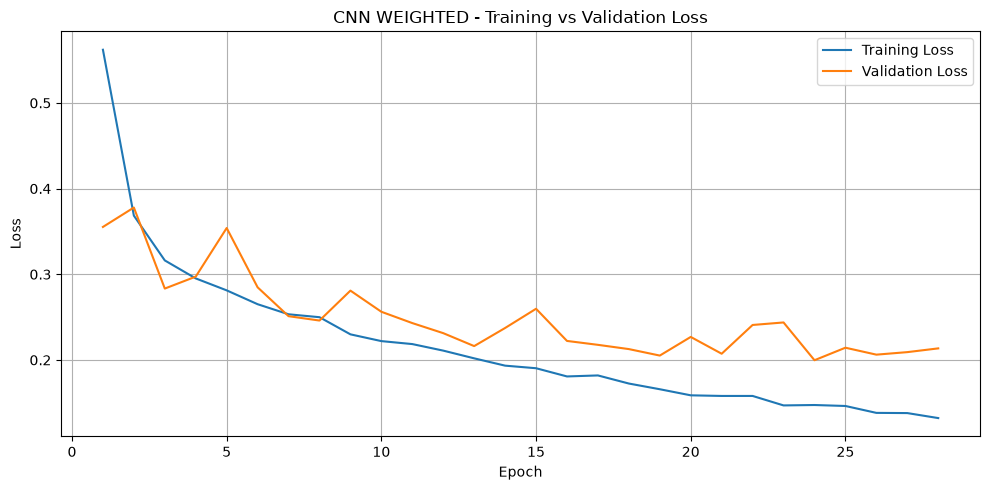

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_weighted_df["epoch"],
    history_weighted_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_weighted_df["epoch"],
    history_weighted_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN WEIGHTED - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_weighted_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

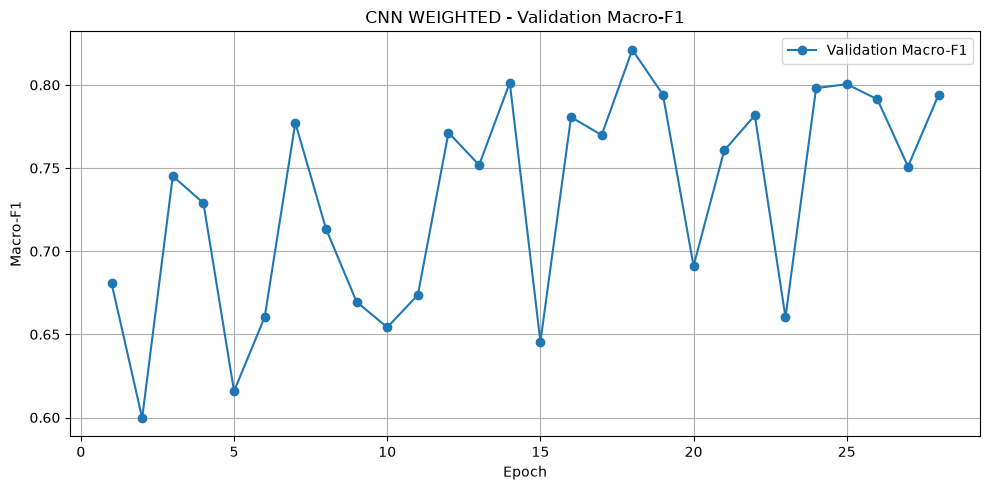

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_weighted_df["epoch"],
    history_weighted_df["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("CNN WEIGHTED - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_weighted_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. CNN Results and Comparison

The two CNN experiments are evaluated using validation classification reports and confusion matrices.

### Key observations

The standard CNN achieved approximately 98.48% validation accuracy and 91.78% Macro-F1.

The weighted CNN achieved approximately 95.36% validation accuracy and 82.12% Macro-F1.

Class weighting increased recall for some minority categories, including Supraventricular and Fusion.

However, this improvement came with a considerable reduction in precision, indicating that the weighted model produced more false-positive predictions.

The results demonstrate that class weighting does not automatically improve overall minority-class F1-score.

It must be evaluated using multiple class-wise metrics.

## 9. Conclusion

The experiments demonstrate that a 1D CNN can learn useful morphological representations from ECG signals.

The standard CNN outperformed the weighted CNN in terms of validation Macro-F1 and overall accuracy.

Although class weighting improved recall for certain minority classes, it also increased false-positive predictions.

These findings motivate the investigation of recurrent architectures, which are explored in the subsequent LSTM and GRU notebook.